
#Will a Savings Plan Reach Its Goal Under Uncertain Returns and Inflation?

## 1. Title and Summary

This project develops a Monte Carlo simulation to estimate the probability
that a regular savings plan reaches a financial target under uncertain
investment returns and inflation.

The model includes initial savings, monthly contributions, investment
return uncertainty, inflation, and changes between simplified market
regimes represented by a discrete-time Markov chain.

The simulation will compare alternative savings strategies, quantify
uncertainty in the estimated probability of success, and verify the
implementation using deterministic calculations and additional numerical
checks.

All initial financial parameters are illustrative assumptions rather
than investment forecasts or financial advice.



## 2. Problem and Research Question

### Research question

How do monthly contributions, investment-return uncertainty, inflation,
and changing market regimes affect the probability of reaching a savings
target within a fixed period?

### Scope

The model represents savings accumulation month by month. Investment
returns and inflation are uncertain, and market conditions can change
between simplified regimes.

The model uses assumed parameters and is intended to investigate
simulation behaviour rather than predict an individual's actual financial
outcome.

### Initial illustrative parameters

- Initial savings: LKR 100,000
- Monthly contribution: LKR 15,000
- Savings target in today's purchasing power: LKR 5,000,000
- Investment period: 10 years
- Number of Monte Carlo paths: 10,000
- Random seed: 42



## 3. Model, Assumptions and Equations

### 3.1 Monthly Savings Balance

Let $B_t$ represent the nominal savings balance at the beginning of month $t$, $C$ the fixed monthly contribution, and $r_t$ the investment return during month $t$.

Investment returns are applied first, followed by the monthly contribution:

$$
B_{t+1}=B_t(1+r_t)+C
$$

The simulation uses monthly time steps over a fixed investment horizon of 10 years (120 months).

### 3.2 Stochastic Investment Returns

Investment returns are modelled using Geometric Brownian Motion (GBM):

$$
\frac{dS}{S}=\mu\,dt+\sigma\,dW
$$

Where:

- $\mu$ = annual GBM drift.
- $\sigma$ = annual volatility.
- $W$ = standard Wiener process.

The model considers two market regimes: Low-return and High-return. Each regime has different drift and volatility parameters.

For a monthly time step, the log-return is generated as:

$$
X_t^r=
\left(\mu_{j_t}-\frac{\sigma_{j_t}^{2}}{2}\right)\frac{1}{12}
+
\frac{\sigma_{j_t}}{\sqrt{12}}Z_t
$$

Where:

- $X_t^r$ = monthly log-investment return.
- $j_t$ = current market regime.
- $Z_t\sim N(0,1)$ = standard normal random variable.
- $\mu_{j_t}$ = annual drift for the current regime.
- $\sigma_{j_t}$ = annual volatility for the current regime.

The monthly investment return is obtained using:

$$
r_t=\exp(X_t^r)-1
$$

The variance adjustment $\frac{\sigma^2}{2}$ converts the GBM drift into the mean log-growth rate.

### 3.3 Markov-Chain Market Regimes

Market conditions are represented by a two-state discrete-time Markov chain (DTMC).

The transition probability matrix is:

$$
P=
\begin{bmatrix}
0.90 & 0.10\\
0.15 & 0.85
\end{bmatrix}
$$

Each row represents the current regime, while each column represents the next month's regime.

The two regimes are:

1. Low-return regime.
2. High-return regime.

The main simulation starts every path in the Low-return regime. Subsequent regimes are selected according to the transition probabilities.

The transition matrix represents the probability of remaining in or moving between market regimes from one month to the next.

### 3.4 Stochastic Inflation

Inflation is also modelled using Geometric Brownian Motion (GBM), with an annual drift of 5% and annual volatility of 2%.

The monthly log-inflation is generated as:

$$
X_t^\pi=
\left(\mu_\pi-\frac{\sigma_\pi^2}{2}\right)\frac{1}{12}
+
\frac{\sigma_\pi}{\sqrt{12}}Y_t
$$

Where:

- $X_t^\pi$ = monthly log-inflation.
- $\mu_\pi$ = annual inflation drift.
- $\sigma_\pi$ = annual inflation volatility.
- $Y_t\sim N(0,1)$ = standard normal random variable.

The monthly inflation rate is obtained using:

$$
\pi_t=\exp(X_t^\pi)-1
$$

Investment-return and inflation shocks are generated independently in the current implementation.

### 3.5 Real Savings Balance

Let $\pi_t$ denote the monthly inflation rate. The cumulative inflation factor after $T$ months is:

$$
I_T=\prod_{t=1}^{T}(1+\pi_t)
$$

The final nominal savings balance is converted into today's purchasing power:

$$
B_T^{\mathrm{real}}=\frac{B_T}{I_T}
$$

This adjustment allows the final savings balance to be evaluated in terms of its purchasing power rather than its nominal value.

### 3.6 Probability of Reaching the Target

Let $G$ represent the savings target in today's purchasing power.

A simulation path is considered successful if:

$$
B_{T,i}^{\mathrm{real}}\geq G
$$

For $N$ independent simulation paths, the estimated probability of success is:

$$
\hat{p}=\frac{1}{N}\sum_{i=1}^{N}
\mathbf{1}\left(B_{T,i}^{\mathrm{real}}\geq G\right)
$$

Where $\mathbf{1}(\cdot)$ is an indicator function that equals 1 when the condition is true and 0 otherwise.

The approximate Monte Carlo standard error is:

$$
SE(\hat{p})=
\sqrt{\frac{\hat{p}(1-\hat{p})}{N}}
$$

A 95% Wilson confidence interval is also calculated to quantify uncertainty in the estimated success probability.

The model combines input modelling and random variate generation, Monte Carlo simulation and a discrete-time Markov chain to investigate how uncertain investment returns, inflation and changing market conditions affect the likelihood of achieving a long-term savings goal.



## 3.7 Model Assumptions and Parameter Justification

The model uses the following simplifying assumptions:

1. The simulation operates in monthly time steps over a fixed investment horizon.
2. Monthly contributions are constant and are added after applying the monthly investment return.
3. Investment returns are generated from a lognormal gross-return model, with parameters determined by the current market regime.
4. Market regimes follow a two-state discrete-time Markov chain with a fixed transition matrix.
5. Monthly inflation is generated stochastically using a lognormal gross-inflation model.
6. Inflation and investment-return shocks are generated independently in this implementation.
7. Contributions are made at the end of each month and are not increased with inflation.
8. Taxes, fees, withdrawals, contribution interruptions and changes in personal circumstances are excluded.
9. All financial parameters are illustrative assumptions until supported by appropriate references.
10. The results are conditional on the assumptions and do not constitute financial advice or a guaranteed forecast.

The model is intended to study how uncertainty and parameter choices affect the probability of reaching a savings target, rather than to predict an individual's actual financial outcome.


### 3.8 Modelling Concepts Applied

The simulation applies the following modelling concepts:

| Concept | Application in This Project |
|---|---|
| Input Modelling and Random Variate Generation | Normal random variables represent uncertain investment returns and inflation using Geometric Brownian Motion. |
| Monte Carlo Simulation | Multiple independent simulation paths estimate the probability of reaching the savings target and the distribution of final savings. |
| Discrete-Time Markov Chains | A two-state Markov chain models transitions between Low-return and High-return market regimes. |

## 4. Implementation

This section implements the monthly savings model using Python. NumPy is used for random number generation and numerical calculations, while Matplotlib is used to visualise simulation results.

In [138]:

import numpy as np
import matplotlib.pyplot as plt

INITIAL_SAVINGS = 100_000.0       # LKR
MONTHLY_CONTRIBUTION = 15_000.0  # LKR
TARGET_REAL = 5_000_000.0        # LKR in today's purchasing power
YEARS = 10
N_PATHS = 10_000
SEED = 42

MONTHS = 12 * YEARS

# Annual GBM drift and volatility parameters by market regime.
# These are illustrative assumptions, not market estimates.
REGIME_NAMES = ["Low-return", "High-return"]

ANNUAL_RETURN_DRIFT = np.array([0.03, 0.09])
ANNUAL_RETURN_VOLATILITY = np.array([0.12, 0.18])

# Rows represent current regimes; columns represent next-month regimes.
TRANSITION_MATRIX = np.array([
    [0.90, 0.10],
    [0.15, 0.85]
])

# Illustrative annual GBM inflation drift and volatility.
ANNUAL_INFLATION_DRIFT = 0.05
ANNUAL_INFLATION_VOLATILITY = 0.02


# Basic parameter checks.
assert INITIAL_SAVINGS >= 0
assert MONTHLY_CONTRIBUTION >= 0
assert TARGET_REAL > 0
assert YEARS > 0 and N_PATHS > 0
assert np.allclose(TRANSITION_MATRIX.sum(axis=1), 1.0)
assert np.all(TRANSITION_MATRIX >= 0)

print("Parameters loaded successfully.")
print(f"Simulation horizon: {MONTHS} months")
print(f"Monte Carlo paths: {N_PATHS:,}")


Parameters loaded successfully.
Simulation horizon: 120 months
Monte Carlo paths: 10,000


In [139]:

# 4.1 Deterministic savings calculation

def deterministic_savings(
    initial_balance,
    monthly_contribution,
    monthly_return,
    months
):
    """Calculate nominal savings with a fixed monthly return."""
    balance = float(initial_balance)

    for _ in range(months):
        balance = balance * (1.0 + monthly_return)
        balance += monthly_contribution

    return balance


# Verification test: zero return means contributions simply accumulate.
test_balance = deterministic_savings(
    initial_balance=1000,
    monthly_contribution=100,
    monthly_return=0.0,
    months=12
)

expected_balance = 1000 + 12 * 100

assert np.isclose(test_balance, expected_balance), (
    f"Expected {expected_balance}, got {test_balance}"
)

print(f"Deterministic test balance: {test_balance:.2f}")
print("PASS: zero-return savings verification.")


Deterministic test balance: 2200.00
PASS: zero-return savings verification.


In [140]:

# 4.2 Monte Carlo simulation

def simulate_savings(
    n_paths=N_PATHS,
    years=YEARS,
    initial_savings=INITIAL_SAVINGS,
    monthly_contribution=MONTHLY_CONTRIBUTION,
    target_real=TARGET_REAL,
    seed=SEED,
):
    """
    Simulate savings paths with Markov-chain market regimes
    and uncertain monthly inflation.

    Returns a dictionary containing nominal and real final balances,
    success indicators, and regime histories.
    """
    if n_paths <= 0 or years <= 0:
        raise ValueError("n_paths and years must be positive.")
    if initial_savings < 0 or monthly_contribution < 0:
        raise ValueError("Savings and contributions cannot be negative.")
    if target_real <= 0:
        raise ValueError("target_real must be positive.")

    rng = np.random.default_rng(seed)
    months = 12 * years

    balances = np.full(n_paths, float(initial_savings))
    inflation_factors = np.ones(n_paths)

    # Start every path in the low-return regime.
    regimes = np.zeros(n_paths, dtype=int)
    regime_history = np.zeros((n_paths, months), dtype=int)

    for month in range(months):
        # Transition to the regime for this month.
        if month > 0:
            transition_draws = rng.random(n_paths)
            probability_of_high = TRANSITION_MATRIX[regimes, 1]
            regimes = (
                transition_draws < probability_of_high
            ).astype(int)

        regime_history[:, month] = regimes

        # Generate investment log returns for the current regimes.
        mu = ANNUAL_RETURN_DRIFT[regimes]
        sigma = ANNUAL_RETURN_VOLATILITY[regimes]

        monthly_log_return = (
            (mu - 0.5 * sigma**2) / 12
            + (sigma / np.sqrt(12)) * rng.standard_normal(n_paths)
        )
        monthly_returns = np.expm1(monthly_log_return)

        # Generate uncertain monthly inflation.
        monthly_log_inflation = (
            (ANNUAL_INFLATION_DRIFT
            - 0.5 * ANNUAL_INFLATION_VOLATILITY**2) / 12
            + (ANNUAL_INFLATION_VOLATILITY / np.sqrt(12))
            * rng.standard_normal(n_paths)
        )
        monthly_inflation = np.expm1(monthly_log_inflation)

        # Apply investment returns, then add the monthly contribution.
        balances = balances * (1.0 + monthly_returns)
        balances += monthly_contribution

        # Track the cumulative loss of purchasing power.
        inflation_factors *= (1.0 + monthly_inflation)

    real_final_balances = balances / inflation_factors
    success = real_final_balances >= target_real

    return {
        "nominal_final": balances,
        "real_final": real_final_balances,
        "inflation_factors": inflation_factors,
        "success": success,
        "regime_history": regime_history,
    }


results = simulate_savings()

print("Simulation completed.")
print(f"Paths simulated: {len(results['real_final']):,}")


Simulation completed.
Paths simulated: 10,000


## 5. Verification

This section verifies the correctness and reliability of the simulation using deterministic test cases, mathematical checks and reproducibility tests. The implementation is also checked against expected numerical properties to ensure that the simulation produces valid and consistent results.

In [141]:
def wilson_interval(successes, total, z=1.96):
    """Calculate a Wilson confidence interval for a binomial proportion."""
    if total <= 0:
        raise ValueError("total must be positive.")

    p_hat = successes / total
    denominator = 1.0 + z**2 / total

    center = (
        p_hat + z**2 / (2.0 * total)
    ) / denominator

    half_width = (
        z * np.sqrt(
            p_hat * (1.0 - p_hat) / total
            + z**2 / (4.0 * total**2)
        ) / denominator
    )

    return max(0.0, center - half_width), min(1.0, center + half_width)


successes = int(np.sum(results["success"]))
p_hat = successes / N_PATHS
ci_low, ci_high = wilson_interval(successes, N_PATHS)

print(f"Successful paths: {successes:,} / {N_PATHS:,}")
print(f"Estimated probability of reaching target: {p_hat:.2%}")
print(f"95% Wilson confidence interval: [{ci_low:.2%}, {ci_high:.2%}]")
print(f"Mean final real savings: LKR {np.mean(results['real_final']):,.2f}")
print(f"Median final real savings: LKR {np.median(results['real_final']):,.2f}")

# Verification checks for the simulation output.
assert len(results["real_final"]) == N_PATHS
assert np.all(np.isfinite(results["real_final"]))
assert np.all(results["real_final"] >= 0)
assert 0.0 <= p_hat <= 1.0
assert ci_low <= p_hat <= ci_high

print("PASS: output validity and probability checks.")


Successful paths: 1 / 10,000
Estimated probability of reaching target: 0.01%
95% Wilson confidence interval: [0.00%, 0.06%]
Mean final real savings: LKR 1,558,454.36
Median final real savings: LKR 1,472,579.92
PASS: output validity and probability checks.


In [142]:
# X2 — Independent deterministic verification

def closed_form_savings(
    initial_balance,
    monthly_contribution,
    monthly_return,
    months
):
    """
    Independent closed-form calculation.

    Assumes the balance earns the fixed return first, then receives
    the contribution at the end of each month.
    """
    B0 = float(initial_balance)
    C = float(monthly_contribution)
    r = float(monthly_return)
    T = int(months)

    if T < 0:
        raise ValueError("months cannot be negative.")
    if r <= -1:
        raise ValueError("monthly_return must be greater than -1.")

    if r == 0:
        return B0 + T * C

    return B0 * (1 + r)**T + C * (((1 + r)**T - 1) / r)


# Test 1: zero returns
test_cases = [
    {
        "name": "Zero return",
        "initial": 1000.0,
        "contribution": 100.0,
        "rate": 0.0,
        "months": 12
    },
    {
        "name": "Positive fixed return",
        "initial": 1000.0,
        "contribution": 100.0,
        "rate": 0.01,
        "months": 12
    },
    {
        "name": "No contributions",
        "initial": 5000.0,
        "contribution": 0.0,
        "rate": 0.02,
        "months": 24
    }
]

for case in test_cases:
    iterative = deterministic_savings(
        initial_balance=case["initial"],
        monthly_contribution=case["contribution"],
        monthly_return=case["rate"],
        months=case["months"]
    )

    closed_form = closed_form_savings(
        initial_balance=case["initial"],
        monthly_contribution=case["contribution"],
        monthly_return=case["rate"],
        months=case["months"]
    )

    error = abs(iterative - closed_form)

    print(f"\nTest: {case['name']}")
    print(f"Iterative result:  {iterative:.10f}")
    print(f"Closed-form result: {closed_form:.10f}")
    print(f"Absolute difference: {error:.12g}")

    assert np.isclose(
        iterative, closed_form,
        rtol=1e-10, atol=1e-8
    ), f"Verification failed: {case['name']}"

print("\nPASS: all independent deterministic verification tests.")



Test: Zero return
Iterative result:  2200.0000000000
Closed-form result: 2200.0000000000
Absolute difference: 0

Test: Positive fixed return
Iterative result:  2395.0753314517
Closed-form result: 2395.0753314517
Absolute difference: 4.54747350886e-13

Test: No contributions
Iterative result:  8042.1862473761
Closed-form result: 8042.1862473761
Absolute difference: 4.54747350886e-12

PASS: all independent deterministic verification tests.



### X2 — Independent Numerical Verification

The savings model is verified against an independent closed-form calculation.

For zero investment returns, the final balance must equal the initial savings plus all monthly contributions:

$$
B_T = B_0 + TC
$$

For a fixed positive monthly return, the expected balance is calculated using a geometric-series equation and compared with the iterative savings function.

Three test cases are used to check zero returns, positive fixed returns, and zero contributions. The results are compared using a numerical tolerance.

These checks independently verify the savings balance-update calculation without relying on random-number generation.


In [143]:

# 5.1 Markov-chain and reproducibility checks

# Each row of the transition matrix must be a probability distribution.
assert np.allclose(TRANSITION_MATRIX.sum(axis=1), 1.0)
assert np.all(TRANSITION_MATRIX >= 0)
assert np.all(TRANSITION_MATRIX <= 1)

# A repeated run with the same seed must reproduce the same results.
repeat_results = simulate_savings(seed=SEED)

assert np.array_equal(
    results["real_final"],
    repeat_results["real_final"]
)
assert np.array_equal(
    results["regime_history"],
    repeat_results["regime_history"]
)

print("PASS: transition matrix is valid.")
print("PASS: fixed-seed simulation is reproducible.")


PASS: transition matrix is valid.
PASS: fixed-seed simulation is reproducible.


## 6. Experiments and Results

This section presents the results of the Monte Carlo simulation and investigates how different financial assumptions affect the probability of achieving the savings target. The experiments examine the distribution of final savings, monthly contribution levels, inflation assumptions, market-regime behaviour and simulation uncertainty.

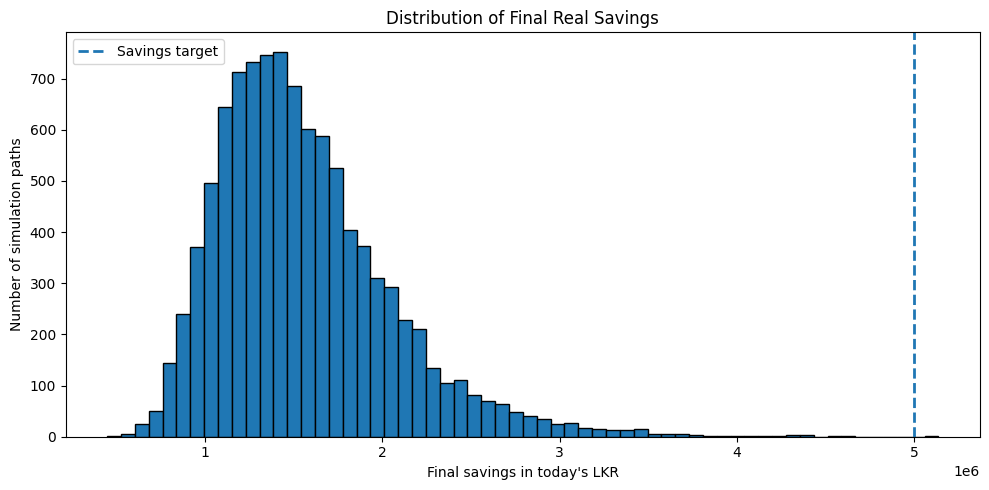

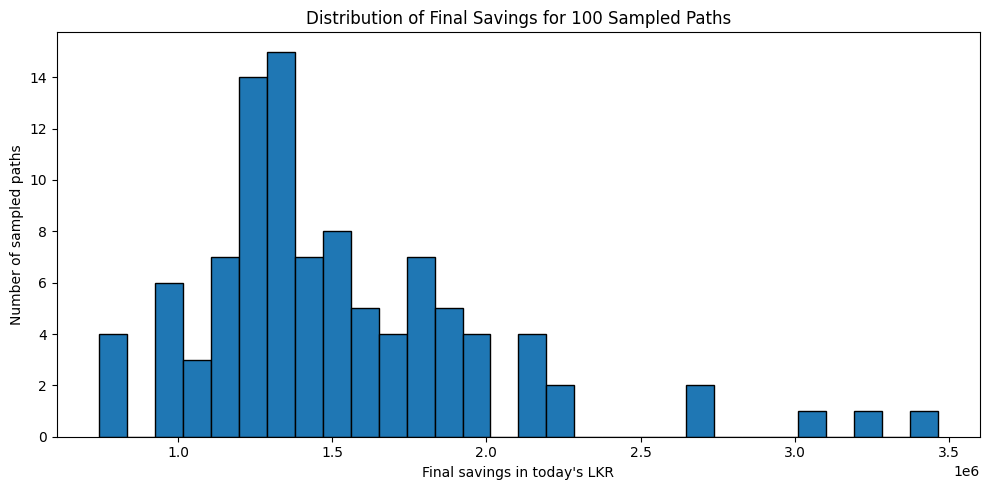

In [144]:
plt.figure(figsize=(10, 5))
plt.hist(
    results["real_final"],
    bins=60,
    edgecolor="black"
)
plt.axvline(
    TARGET_REAL,
    linestyle="--",
    linewidth=2,
    label="Savings target"
)
plt.xlabel("Final savings in today's LKR")
plt.ylabel("Number of simulation paths")
plt.title("Distribution of Final Real Savings")
plt.legend()
plt.tight_layout()
plt.show()

# Show a representative set of paths.
# This is a visual sample, not a separate probability estimate.
plt.figure(figsize=(10, 5))

sample_count = min(100, N_PATHS)
sample_indices = np.arange(sample_count)

plt.hist(
    results["real_final"][sample_indices],
    bins=30,
    edgecolor="black"
)
plt.xlabel("Final savings in today's LKR")
plt.ylabel("Number of sampled paths")
plt.title("Distribution of Final Savings for 100 Sampled Paths")
plt.tight_layout()
plt.show()


In [145]:
# 6.1 Sensitivity to monthly contributions

CONTRIBUTION_SCENARIOS = [10_000, 15_000, 25_000]
SCENARIO_PATHS = 10_000

scenario_results = []

for contribution in CONTRIBUTION_SCENARIOS:
    scenario = simulate_savings(
        n_paths=SCENARIO_PATHS,
        years=YEARS,
        initial_savings=INITIAL_SAVINGS,
        monthly_contribution=contribution,
        target_real=TARGET_REAL,
        seed=SEED,
    )

    count = int(np.sum(scenario["success"]))
    probability = count / SCENARIO_PATHS
    lower, upper = wilson_interval(count, SCENARIO_PATHS)

    scenario_results.append({
        "Monthly contribution (LKR)": contribution,
        "Estimated success probability": probability,
        "95% CI lower": lower,
        "95% CI upper": upper,
        "Median final real savings (LKR)": float(
            np.median(scenario["real_final"])
        ),
    })

for row in scenario_results:
    print(
        f"Contribution: LKR {row['Monthly contribution (LKR)']:,.0f} | "
        f"Success: {row['Estimated success probability']:.2%} | "
        f"95% CI: "
        f"[{row['95% CI lower']:.2%}, "
        f"{row['95% CI upper']:.2%}] | "
        f"Median real savings: "
        f"LKR {row['Median final real savings (LKR)']:,.2f}"
    )


Contribution: LKR 10,000 | Success: 0.00% | 95% CI: [0.00%, 0.04%] | Median real savings: LKR 1,013,056.74
Contribution: LKR 15,000 | Success: 0.01% | 95% CI: [0.00%, 0.06%] | Median real savings: LKR 1,472,579.92
Contribution: LKR 25,000 | Success: 1.19% | 95% CI: [1.00%, 1.42%] | Median real savings: LKR 2,391,224.14


Monthly contribution: LKR  10,000 | Success probability:   0.00% | 95% CI: [0.00%, 0.04%]
Monthly contribution: LKR  15,000 | Success probability:   0.01% | 95% CI: [0.00%, 0.06%]
Monthly contribution: LKR  25,000 | Success probability:   1.19% | 95% CI: [1.00%, 1.42%]
Monthly contribution: LKR  35,000 | Success probability:   8.64% | 95% CI: [8.11%, 9.21%]
Monthly contribution: LKR  50,000 | Success probability:  41.49% | 95% CI: [40.53%, 42.46%]
Monthly contribution: LKR  75,000 | Success probability:  88.41% | 95% CI: [87.77%, 89.02%]
Monthly contribution: LKR 100,000 | Success probability:  98.77% | 95% CI: [98.53%, 98.97%]


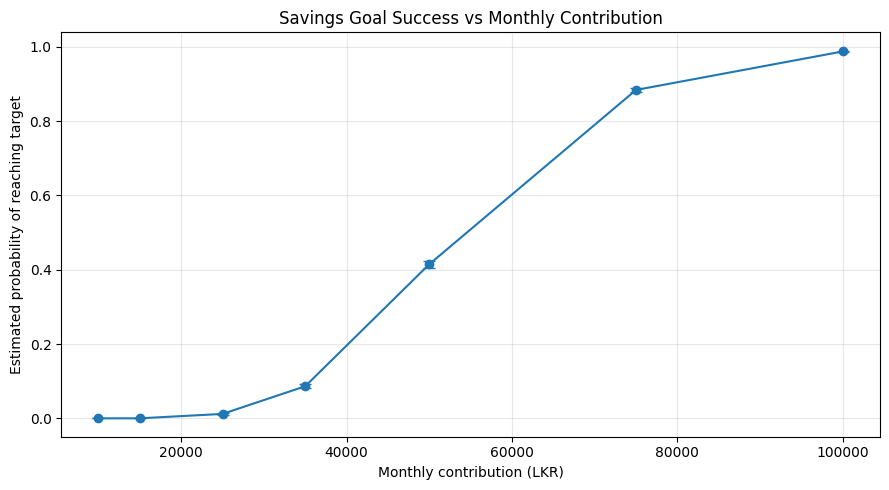

In [146]:

# 6.2 Extended sensitivity analysis:
# Effect of monthly contribution on the goal-reaching probability

CONTRIBUTION_LEVELS = [
    10_000, 15_000, 25_000,
    35_000, 50_000, 75_000, 100_000
]

SENSITIVITY_PATHS = 10_000
sensitivity_results = []

for contribution in CONTRIBUTION_LEVELS:
    scenario = simulate_savings(
        n_paths=SENSITIVITY_PATHS,
        years=YEARS,
        initial_savings=INITIAL_SAVINGS,
        monthly_contribution=contribution,
        target_real=TARGET_REAL,
        seed=SEED
    )

    successes = int(np.sum(scenario["success"]))
    probability = successes / SENSITIVITY_PATHS
    lower, upper = wilson_interval(
        successes, SENSITIVITY_PATHS
    )

    sensitivity_results.append({
        "contribution": contribution,
        "probability": probability,
        "lower": lower,
        "upper": upper,
        "median": float(np.median(scenario["real_final"]))
    })

for row in sensitivity_results:
    print(
        f"Monthly contribution: LKR {row['contribution']:>7,.0f} | "
        f"Success probability: {row['probability']:>7.2%} | "
        f"95% CI: [{row['lower']:.2%}, {row['upper']:.2%}]"
    )

# Plot success probability with confidence intervals.
x = np.array([r["contribution"] for r in sensitivity_results])
p = np.array([r["probability"] for r in sensitivity_results])
lo = np.array([r["lower"] for r in sensitivity_results])
hi = np.array([r["upper"] for r in sensitivity_results])

plt.figure(figsize=(9, 5))
plt.errorbar(
    x, p,
    yerr=np.vstack([p - lo, hi - p]),
    marker="o",
    capsize=4
)
plt.xlabel("Monthly contribution (LKR)")
plt.ylabel("Estimated probability of reaching target")
plt.title("Savings Goal Success vs Monthly Contribution")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


N=  500 | Mean p=40.9740% | Empirical SE=0.021448 | Theoretical SE=0.021993
N= 1000 | Mean p=41.3770% | Empirical SE=0.014353 | Theoretical SE=0.015574
N= 2000 | Mean p=41.2470% | Empirical SE=0.011701 | Theoretical SE=0.011008
N= 5000 | Mean p=41.2638% | Empirical SE=0.006283 | Theoretical SE=0.006962
N=10000 | Mean p=41.3232% | Empirical SE=0.004830 | Theoretical SE=0.004924

Improved measured log-log slope: -0.503
Expected asymptotic slope: -0.500


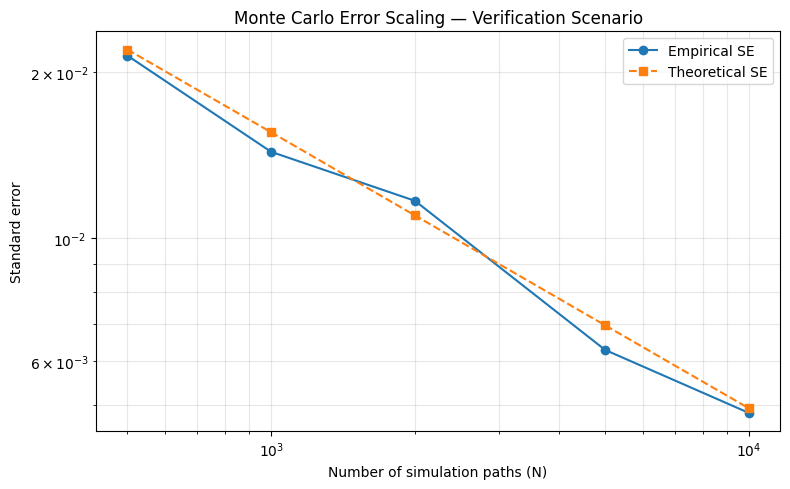

In [147]:

# X2 — Improved error-scaling experiment
# Use a fixed, more informative scenario for verification.
# This does not change the baseline model or its reported results.

VERIFICATION_CONTRIBUTION = 50_000
SAMPLE_SIZES_X2 = [500, 1000, 2000, 5000, 10000]
REPLICATIONS_X2 = 100

x2_results = []

for n in SAMPLE_SIZES_X2:
    estimates = []

    for rep in range(REPLICATIONS_X2):
        trial = simulate_savings(
            n_paths=n,
            years=YEARS,
            initial_savings=INITIAL_SAVINGS,
            monthly_contribution=VERIFICATION_CONTRIBUTION,
            target_real=TARGET_REAL,
            seed=20_000 + rep
        )
        estimates.append(np.mean(trial["success"]))

    estimates = np.asarray(estimates)
    empirical_se = np.std(estimates, ddof=1)
    mean_p = np.mean(estimates)
    theoretical_se = np.sqrt(mean_p * (1 - mean_p) / n)

    x2_results.append({
        "N": n,
        "mean_p": mean_p,
        "empirical_se": empirical_se,
        "theoretical_se": theoretical_se
    })

for row in x2_results:
    print(
        f"N={row['N']:>5} | "
        f"Mean p={row['mean_p']:.4%} | "
        f"Empirical SE={row['empirical_se']:.6f} | "
        f"Theoretical SE={row['theoretical_se']:.6f}"
    )

sizes = np.array([r["N"] for r in x2_results])
emp = np.array([r["empirical_se"] for r in x2_results])
theory = np.array([r["theoretical_se"] for r in x2_results])

valid = emp > 0
slope, intercept = np.polyfit(
    np.log(sizes[valid]),
    np.log(emp[valid]),
    1
)

print(f"\nImproved measured log-log slope: {slope:.3f}")
print("Expected asymptotic slope: -0.500")

plt.figure(figsize=(8, 5))
plt.loglog(sizes, emp, "o-", label="Empirical SE")
plt.loglog(sizes, theory, "s--", label="Theoretical SE")
plt.xlabel("Number of simulation paths (N)")
plt.ylabel("Standard error")
plt.title("Monte Carlo Error Scaling — Verification Scenario")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [148]:

# X3 — Markov-chain transition verification

def verify_transition_matrix(
    transition_matrix,
    n_transitions=200_000,
    seed=12345
):
    """Compare simulated transition frequencies with theoretical values."""
    rng = np.random.default_rng(seed)
    n_states = transition_matrix.shape[0]

    assert transition_matrix.shape == (n_states, n_states)
    assert np.all(transition_matrix >= 0)
    assert np.allclose(transition_matrix.sum(axis=1), 1.0)

    # Simulate transitions starting from each possible state.
    observed = np.zeros_like(transition_matrix, dtype=int)

    for state in range(n_states):
        draws = rng.random(n_transitions)
        cumulative = np.cumsum(transition_matrix[state])
        next_states = np.searchsorted(cumulative, draws, side="right")

        observed[state] = np.bincount(
            next_states, minlength=n_states
        )

    empirical = observed / n_transitions

    print("Theoretical transition matrix:")
    print(transition_matrix)

    print("\nEmpirical transition matrix:")
    print(empirical)

    print("\nAbsolute errors:")
    print(np.abs(empirical - transition_matrix))

    return empirical


empirical_transition_matrix = verify_transition_matrix(
    TRANSITION_MATRIX
)

# A generous statistical tolerance for this large sample.
assert np.all(
    np.abs(empirical_transition_matrix - TRANSITION_MATRIX) < 0.01
)

print("\nPASS: empirical transitions agree with the specified matrix.")


Theoretical transition matrix:
[[0.9  0.1 ]
 [0.15 0.85]]

Empirical transition matrix:
[[0.899265 0.100735]
 [0.148945 0.851055]]

Absolute errors:
[[0.000735 0.000735]
 [0.001055 0.001055]]

PASS: empirical transitions agree with the specified matrix.


In [149]:

# X3 — Long-run stationary distribution verification

def simulate_markov_chain(
    transition_matrix,
    n_steps=500_000,
    initial_state=0,
    seed=2026
):
    rng = np.random.default_rng(seed)
    n_states = transition_matrix.shape[0]
    states = np.empty(n_steps, dtype=int)

    state = initial_state

    for t in range(n_steps):
        states[t] = state
        state = rng.choice(
            n_states,
            p=transition_matrix[state]
        )

    return states


chain = simulate_markov_chain(TRANSITION_MATRIX)

# Discard an initial burn-in period to reduce dependence on initial state.
burn_in = 5_000
observed_states = chain[burn_in:]
empirical_stationary = np.bincount(
    observed_states, minlength=2
) / len(observed_states)

# Theoretical stationary distribution for this two-state chain.
theoretical_stationary = np.array([0.60, 0.40])

print("Theoretical stationary distribution:", theoretical_stationary)
print("Empirical stationary distribution:  ", empirical_stationary)
print("Absolute errors:                    ",
      np.abs(empirical_stationary - theoretical_stationary))

assert np.all(
    np.abs(empirical_stationary - theoretical_stationary) < 0.01
)

print("PASS: long-run regime proportions agree within tolerance.")


Theoretical stationary distribution: [0.6 0.4]
Empirical stationary distribution:   [0.60230303 0.39769697]
Absolute errors:                     [0.00230303 0.00230303]
PASS: long-run regime proportions agree within tolerance.



Persistent Markov regimes
Successful paths: 1/10,000
Success probability: 0.01%
95% Wilson CI: [0.00%, 0.06%]
Median final real savings: LKR 1,472,579.92
Mean final real savings: LKR 1,558,454.36

Independent monthly regimes
Successful paths: 1/10,000
Success probability: 0.01%
95% Wilson CI: [0.00%, 0.06%]
Median final real savings: LKR 1,485,133.54
Mean final real savings: LKR 1,561,197.53


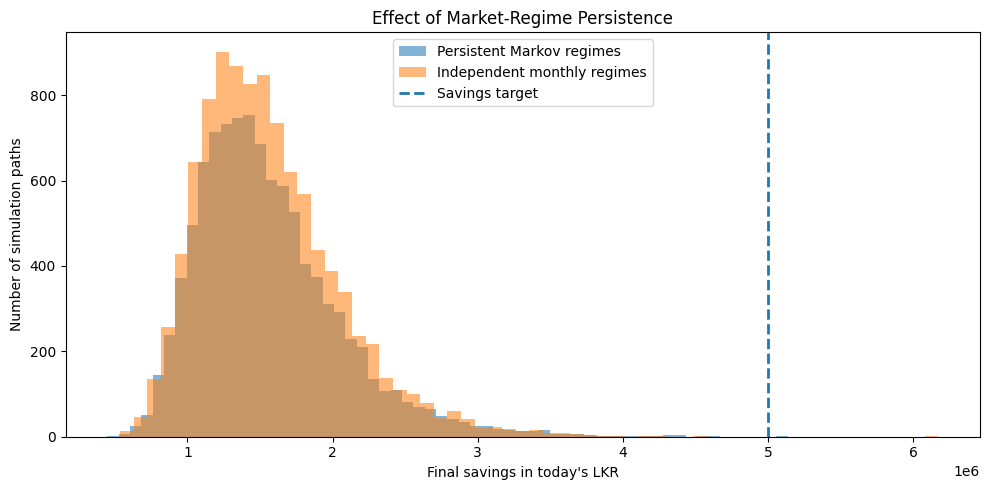


PASS: both models produced valid final savings.


In [150]:

# X3 — Compare persistent Markov regimes with independent regimes


def simulate_savings_iid_regimes(
    n_paths=N_PATHS,
    years=YEARS,
    initial_savings=INITIAL_SAVINGS,
    monthly_contribution=MONTHLY_CONTRIBUTION,
    target_real=TARGET_REAL,
    seed=SEED,
):
    """
    Independent-regime comparison model.

    Every path starts in the Low-return regime, matching the
    Markov model's initial condition.

    For later months, regimes are sampled independently using
    the time-dependent marginal probabilities of the Markov chain.
    This preserves the same monthly regime probabilities while
    removing month-to-month persistence.
    """
    if n_paths <= 0 or years <= 0:
        raise ValueError("n_paths and years must be positive.")
    if initial_savings < 0 or monthly_contribution < 0:
        raise ValueError("Savings and contributions cannot be negative.")
    if target_real <= 0:
        raise ValueError("target_real must be positive.")

    rng = np.random.default_rng(seed)
    months = 12 * years

    balances = np.full(n_paths, float(initial_savings))
    inflation_factors = np.ones(n_paths)
    regime_history = np.zeros((n_paths, months), dtype=int)

    # All paths start in the Low-return regime.
    regime_probabilities = np.array([1.0, 0.0])

    for month in range(months):

        # From the second month onwards, update the theoretical
        # marginal regime probabilities using the transition matrix.
        if month > 0:
            regime_probabilities = (
                regime_probabilities @ TRANSITION_MATRIX
            )

        # Sample independently across paths using the same
        # time-dependent marginal probabilities.
        regimes = rng.choice(
            2,
            size=n_paths,
            p=regime_probabilities
        )

        regime_history[:, month] = regimes

        mu = ANNUAL_RETURN_DRIFT[regimes]
        sigma = ANNUAL_RETURN_VOLATILITY[regimes]

        monthly_log_return = (
            (mu - 0.5 * sigma**2) / 12
            + (sigma / np.sqrt(12))
            * rng.standard_normal(n_paths)
        )
        monthly_returns = np.expm1(monthly_log_return)

        monthly_log_inflation = (
            (ANNUAL_INFLATION_DRIFT
             - 0.5 * ANNUAL_INFLATION_VOLATILITY**2) / 12
            + (ANNUAL_INFLATION_VOLATILITY / np.sqrt(12))
            * rng.standard_normal(n_paths)
        )
        monthly_inflation = np.expm1(monthly_log_inflation)

        balances = balances * (1.0 + monthly_returns)
        balances += monthly_contribution
        inflation_factors *= (1.0 + monthly_inflation)

    real_final = balances / inflation_factors
    success = real_final >= target_real

    return {
        "nominal_final": balances,
        "real_final": real_final,
        "inflation_factors": inflation_factors,
        "success": success,
        "regime_history": regime_history,
    }



# Run both models with the same financial assumptions.
markov_comparison = simulate_savings(seed=SEED)

iid_comparison = simulate_savings_iid_regimes(seed=SEED)


def summarize_model(label, model_results):
    n = len(model_results["success"])
    successes = int(np.sum(model_results["success"]))
    p = successes / n
    lower, upper = wilson_interval(successes, n)

    return {
        "Model": label,
        "Successful paths": successes,
        "Success probability": p,
        "95% CI lower": lower,
        "95% CI upper": upper,
        "Median final real savings": float(
            np.median(model_results["real_final"])
        ),
        "Mean final real savings": float(
            np.mean(model_results["real_final"])
        ),
    }


comparison = [
    summarize_model("Persistent Markov regimes", markov_comparison),
    summarize_model("Independent monthly regimes", iid_comparison),
]

for row in comparison:
    print(f"\n{row['Model']}")
    print(f"Successful paths: {row['Successful paths']:,}/{N_PATHS:,}")
    print(f"Success probability: {row['Success probability']:.2%}")
    print(
        "95% Wilson CI: "
        f"[{row['95% CI lower']:.2%}, "
        f"{row['95% CI upper']:.2%}]"
    )
    print(
        "Median final real savings: "
        f"LKR {row['Median final real savings']:,.2f}"
    )
    print(
        "Mean final real savings: "
        f"LKR {row['Mean final real savings']:,.2f}"
    )

# Compare the distributions of final real savings.
plt.figure(figsize=(10, 5))

plt.hist(
    markov_comparison["real_final"],
    bins=60,
    alpha=0.55,
    label="Persistent Markov regimes"
)
plt.hist(
    iid_comparison["real_final"],
    bins=60,
    alpha=0.55,
    label="Independent monthly regimes"
)

plt.axvline(
    TARGET_REAL,
    linestyle="--",
    linewidth=2,
    label="Savings target"
)
plt.xlabel("Final savings in today's LKR")
plt.ylabel("Number of simulation paths")
plt.title("Effect of Market-Regime Persistence")
plt.legend()
plt.tight_layout()
plt.show()

# Confirm that both models generated valid outputs.
assert np.all(np.isfinite(markov_comparison["real_final"]))
assert np.all(np.isfinite(iid_comparison["real_final"]))
assert np.all(markov_comparison["real_final"] >= 0)
assert np.all(iid_comparison["real_final"] >= 0)

print("\nPASS: both models produced valid final savings.")


In [151]:

# X3 — Repeated model comparison with uncertainty

X3_REPLICATIONS = 50
X3_PATHS = 5_000
X3_CONTRIBUTION = 50_000

markov_probabilities = []
iid_probabilities = []

for rep in range(X3_REPLICATIONS):
    markov_run = simulate_savings(
        n_paths=X3_PATHS,
        years=YEARS,
        initial_savings=INITIAL_SAVINGS,
        monthly_contribution=X3_CONTRIBUTION,
        target_real=TARGET_REAL,
        seed=30_000 + rep
    )

    iid_run = simulate_savings_iid_regimes(
        n_paths=X3_PATHS,
        years=YEARS,
        initial_savings=INITIAL_SAVINGS,
        monthly_contribution=X3_CONTRIBUTION,
        target_real=TARGET_REAL,
        seed=40_000 + rep
    )

    markov_probabilities.append(np.mean(markov_run["success"]))
    iid_probabilities.append(np.mean(iid_run["success"]))

markov_probabilities = np.array(markov_probabilities)
iid_probabilities = np.array(iid_probabilities)

differences = markov_probabilities - iid_probabilities

def mean_ci(values):
    """Approximate 95% t interval for a replication-level mean."""
    from scipy.stats import t

    values = np.asarray(values)
    n = len(values)
    mean = np.mean(values)
    se = np.std(values, ddof=1) / np.sqrt(n)
    critical = t.ppf(0.975, df=n - 1)

    return mean, mean - critical * se, mean + critical * se

m_mean, m_low, m_high = mean_ci(markov_probabilities)
i_mean, i_low, i_high = mean_ci(iid_probabilities)
d_mean, d_low, d_high = mean_ci(differences)

print("X3 repeated model comparison")
print(f"Replications: {X3_REPLICATIONS}")
print(f"Paths per model per replication: {X3_PATHS:,}")
print(f"Monthly contribution: LKR {X3_CONTRIBUTION:,}")

print(
    f"\nMarkov success probability: {m_mean:.2%}"
    f"\n95% replication-level CI: [{m_low:.2%}, {m_high:.2%}]"
)

print(
    f"\nIndependent-regime success probability: {i_mean:.2%}"
    f"\n95% replication-level CI: [{i_low:.2%}, {i_high:.2%}]"
)

print(
    f"\nDifference (Markov - independent): {d_mean:.2%}"
    f"\n95% CI for difference: [{d_low:.2%}, {d_high:.2%}]"
)

if d_low > 0:
    print("Interpretation: evidence of a higher Markov success probability.")
elif d_high < 0:
    print("Interpretation: evidence of a lower Markov success probability.")
else:
    print("Interpretation: the interval includes zero; no clear difference established.")


X3 repeated model comparison
Replications: 50
Paths per model per replication: 5,000
Monthly contribution: LKR 50,000

Markov success probability: 41.31%
95% replication-level CI: [41.12%, 41.49%]

Independent-regime success probability: 41.52%
95% replication-level CI: [41.31%, 41.73%]

Difference (Markov - independent): -0.21%
95% CI for difference: [-0.50%, 0.07%]
Interpretation: the interval includes zero; no clear difference established.


In [152]:

# X5 — Sensitivity analysis across contribution and inflation

def simulate_sensitivity_case(
    n_paths,
    monthly_contribution,
    annual_inflation_drift,
    seed,
    years=YEARS,
):
    """Run a Markov-regime savings simulation with adjustable inflation."""
    rng = np.random.default_rng(seed)
    months = 12 * years

    balances = np.full(n_paths, INITIAL_SAVINGS, dtype=float)
    inflation_factors = np.ones(n_paths)
    regimes = np.zeros(n_paths, dtype=int)

    for month in range(months):
        if month > 0:
            draws = rng.random(n_paths)
            p_high = TRANSITION_MATRIX[regimes, 1]
            regimes = (draws < p_high).astype(int)

        mu = ANNUAL_RETURN_DRIFT[regimes]
        sigma = ANNUAL_RETURN_VOLATILITY[regimes]

        log_returns = (
            (mu - 0.5 * sigma**2) / 12
            + sigma / np.sqrt(12) * rng.standard_normal(n_paths)
        )
        returns = np.expm1(log_returns)

        log_inflation = (
            (annual_inflation_drift
             - 0.5 * ANNUAL_INFLATION_VOLATILITY**2) / 12
            + ANNUAL_INFLATION_VOLATILITY / np.sqrt(12)
            * rng.standard_normal(n_paths)
        )
        inflation = np.expm1(log_inflation)

        balances = balances * (1 + returns)
        balances += monthly_contribution
        inflation_factors *= (1 + inflation)

    real_final = balances / inflation_factors
    success = real_final >= TARGET_REAL

    return real_final, success


CONTRIBUTION_GRID = [15_000, 25_000, 35_000, 50_000, 75_000]
INFLATION_GRID = [0.02, 0.035, 0.05, 0.065]
X5_PATHS = 10_000

x5_results = []

for inflation_rate in INFLATION_GRID:
    for contribution in CONTRIBUTION_GRID:
        real_final, success = simulate_sensitivity_case(
            n_paths=X5_PATHS,
            monthly_contribution=contribution,
            annual_inflation_drift=inflation_rate,
            seed=50_000
        )

        count = int(np.sum(success))
        p_hat = count / X5_PATHS
        low, high = wilson_interval(count, X5_PATHS)

        x5_results.append({
            "inflation": inflation_rate,
            "contribution": contribution,
            "success_probability": p_hat,
            "ci_low": low,
            "ci_high": high,
            "median_real_savings": float(np.median(real_final))
        })

print("X5 sensitivity results")
print("Each row represents 10,000 simulated paths.\n")

for row in x5_results:
    print(
        f"Annual inflation drift={row['inflation']:.1%} | "
        f"Contribution=LKR {row['contribution']:,} | "
        f"Success={row['success_probability']:.2%} | "
        f"95% CI=[{row['ci_low']:.2%}, {row['ci_high']:.2%}]"
    )


X5 sensitivity results
Each row represents 10,000 simulated paths.

Annual inflation drift=2.0% | Contribution=LKR 15,000 | Success=0.26% | 95% CI=[0.18%, 0.38%]
Annual inflation drift=2.0% | Contribution=LKR 25,000 | Success=7.72% | 95% CI=[7.21%, 8.26%]
Annual inflation drift=2.0% | Contribution=LKR 35,000 | Success=35.49% | 95% CI=[34.56%, 36.43%]
Annual inflation drift=2.0% | Contribution=LKR 50,000 | Success=79.89% | 95% CI=[79.09%, 80.66%]
Annual inflation drift=2.0% | Contribution=LKR 75,000 | Success=99.07% | 95% CI=[98.86%, 99.24%]
Annual inflation drift=3.5% | Contribution=LKR 15,000 | Success=0.05% | 95% CI=[0.02%, 0.12%]
Annual inflation drift=3.5% | Contribution=LKR 25,000 | Success=3.04% | 95% CI=[2.72%, 3.39%]
Annual inflation drift=3.5% | Contribution=LKR 35,000 | Success=19.15% | 95% CI=[18.39%, 19.93%]
Annual inflation drift=3.5% | Contribution=LKR 50,000 | Success=62.55% | 95% CI=[61.60%, 63.49%]
Annual inflation drift=3.5% | Contribution=LKR 75,000 | Success=96.23% 

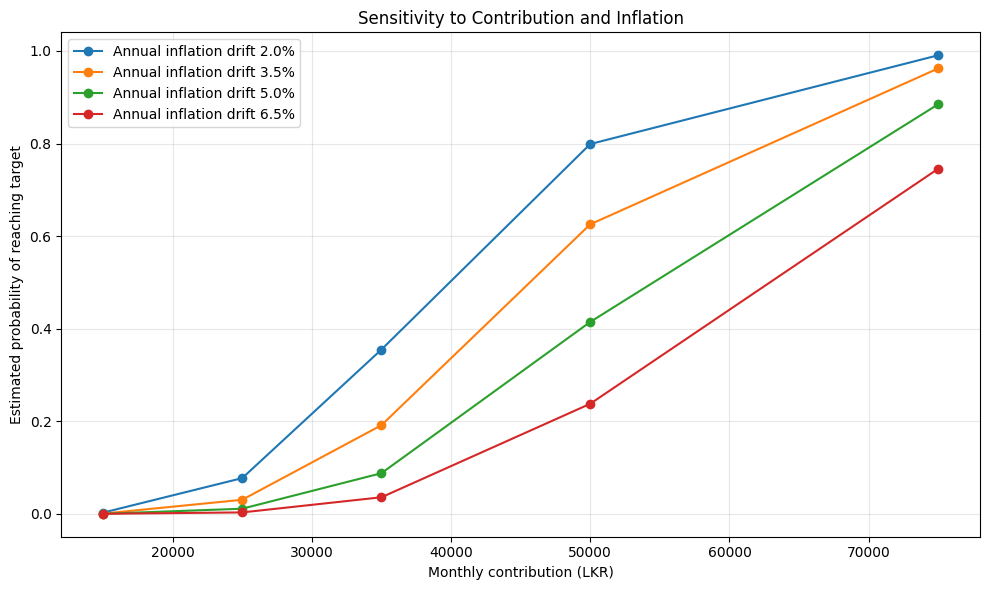

In [153]:

# X5 — Visualise sensitivity to inflation and contribution

plt.figure(figsize=(10, 6))

for inflation_rate in INFLATION_GRID:
    rows = [
        row for row in x5_results
        if row["inflation"] == inflation_rate
    ]
    rows = sorted(rows, key=lambda row: row["contribution"])

    contributions = [row["contribution"] for row in rows]
    probabilities = [row["success_probability"] for row in rows]

    plt.plot(
        contributions,
        probabilities,
        marker="o",
        label=f"Annual inflation drift {inflation_rate:.1%}"
    )

plt.xlabel("Monthly contribution (LKR)")
plt.ylabel("Estimated probability of reaching target")
plt.title("Sensitivity to Contribution and Inflation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Discussion and Limitations

This section interprets the simulation results in relation to the research question. It discusses how monthly contributions, investment-return uncertainty, inflation and market-regime behaviour influence the probability of achieving the savings target. The limitations of the model and the implications of its simplifying assumptions are also considered.


### X3 — Repeated Comparison and Discussion

The persistent Markov-regime model and the independent-regime model were compared using 50 replications, each containing 5,000 simulated paths. Both models used a monthly contribution of LKR 50,000.

The estimated mean success probabilities were 41.31% for the Markov model and 41.52% for the independent-regime model. The estimated difference (Markov minus independent) was -0.21 percentage points, with a 95% replication-level confidence interval from -0.50 to +0.07 percentage points.

Because this interval includes zero, the experiment does not establish a clear difference in success probability under the chosen assumptions. This does not demonstrate equivalence between the models.

The comparison uses matching time-dependent marginal regime probabilities and initial conditions. Therefore, it provides a fairer investigation of the effect of regime persistence.

The result demonstrates the importance of reporting uncertainty when comparing simulation models rather than relying on point estimates alone.



### X3 — Discussion of Market-Regime Persistence

The persistent Markov-regime model and the independent monthly regime model
produced similar savings distributions under the baseline financial
assumptions.

Both models recorded one successful path out of 10,000, corresponding to
an estimated success probability of 0.01%. The median final real savings
were approximately LKR 1.473 million for the persistent model and
LKR 1.486 million for the independent model.

The mean final real savings were approximately LKR 1.558 million and
LKR 1.562 million, respectively. These small differences suggest that
the effect of regime persistence on the mean and median is limited under
this particular parameterisation.

However, the estimated success probability is extremely low, and both
models recorded only one successful path. Consequently, these results
are insufficient to establish a meaningful difference in the probability
of reaching the target. Further investigation using scenarios with more
frequent successes is needed to compare tail outcomes reliably.

The comparison illustrates that the effects of regime persistence depend
on the chosen financial parameters and the outcome being investigated.



### X5 — Sensitivity Analysis Discussion

A two-parameter sensitivity analysis examined five monthly contribution
levels and four annual inflation drift assumptions. Each scenario used
10,000 simulated paths, and a 95% Wilson confidence interval was
calculated for its estimated success probability.

The estimated probability of reaching the savings target increased as
monthly contributions increased. For example, under the 5% annual
inflation drift scenario, the estimated probability increased from
1.11% at LKR 25,000 per month to 88.49% at LKR 75,000 per month.

Inflation also had a substantial effect. At a monthly contribution of
LKR 50,000, the estimated success probability decreased from 79.89%
under the 2% annual inflation drift scenario to 23.78% under the 6.5%
scenario.

These results indicate that both the savings contribution and inflation
assumptions materially affect the estimated probability of reaching the
target. The inflation levels are illustrative scenario assumptions,
not forecasts. The conclusions therefore describe the behaviour of the
specified simulation model rather than guaranteed real-world outcomes.

### 7.1 Overall Model Limitations

The simulation has several limitations that should be considered when interpreting the results. First, the investment return and inflation parameters are based on assumed values rather than calibrated historical market data. Therefore, the results represent illustrative scenarios and should not be treated as actual financial forecasts.

Second, the model assumes that investment returns and inflation evolve independently. In reality, these factors may be related and influenced by economic conditions. The two-state Markov model also simplifies market behaviour into Low and High return regimes, which may not capture all market fluctuations.

Furthermore, the model assumes fixed monthly contributions throughout the investment period. It does not account for changes in income, missed contributions, withdrawals, taxes, management fees or other investment costs. The model also assumes that the investor follows the same savings plan for the entire period.

Future improvements could include calibrating the model using historical financial data, modelling the relationship between returns and inflation, and incorporating realistic changes in contributions, fees and withdrawals. These improvements could provide more realistic estimates of the probability of reaching the savings target.

## 8. References

[1] S. E. Shreve, Stochastic Calculus for Finance II: Continuous-Time Models. New York, NY, USA: Springer, 2004.

[2] P. Glasserman, Monte Carlo Methods in Financial Engineering. New York, NY, USA: Springer, 2003.

[3] J. R. Norris, Markov Chains. Cambridge, U.K.: Cambridge University Press, 1997.

[4] A. M. Law, Simulation Modeling and Analysis, 5th ed. New York, NY, USA: McGraw-Hill Education, 2015.

[5] E. B. Wilson, “Probable inference, the law of succession, and statistical inference,” Journal of the American Statistical Association, vol. 22, no. 158, pp. 209–212, 1927, doi: 10.1080/01621459.1927.10502953.

[6] C. R. Harris et al., “Array programming with NumPy,” Nature, vol. 585, pp. 357–362, 2020, doi: 10.1038/s41586-020-2649-2.

[7] NumPy Developers, “Random Generator,” NumPy documentation. [Online]. Available: https://numpy.org/doc/stable/reference/random/generator.html. [Accessed: Nov. 19, 2026].